In [54]:
import torch
import numpy as np
from matplotlib import pyplot as plt

import sys
sys.path.append("../")
#
import torch.nn as nn

from time import time

import re

from sklearn.decomposition import NMF

from nltk.corpus import stopwords
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

import ssnmf
from ssnmf import SSNMF

import pandas as pd

In [55]:
#"documents" are the individual tweets
tweets = pd.read_csv('../data cleaning/text of tweets.csv',names=["tweet_id","tweet"]) 
documents=tweets["tweet"]

#vectorizer=TfidfVectorizer(stop_words='english')
#stopwords_list+= ["rt", "https://t.co/pIPCd6Nu9s","https://t.co/DdGBGsLBKe","pipcd6nu9s", "ddgbgslbke", "https"]

#Possible experiment: more or fewer stopwords removed.
stopwords_list=stopwords.words("english")
stopwords_list+= ["rt", "RT"]

#additional cleaning for web addresses
def cleaner(s):
    out=re.sub(r'http.*\s?', '',s)
    out=re.sub(r'\s\d+','',out)
    out=re.sub(r':\d+','',out)
    out= out.lower()
    return out
#vectorizer=TfidfVectorizer(stop_words=stopwords_list, preprocessor=lambda s: re.sub(r'http.*\s?', '',s).lower())
vectorizer=TfidfVectorizer(stop_words=stopwords_list,preprocessor=cleaner)

vectors = vectorizer.fit_transform(documents)

idx_to_word = np.array(vectorizer.get_feature_names_out())

np.save("../NMF/all_tweets.npy", vectors)
np.save("../NMF/all_tweets_words.npy", idx_to_word)

In [56]:


def d_to_v(d, verbose=True):
    """
    Given dictionary d of form {word: weight}, created GT topic vector v. See writeup for details.
    """
    l = list(idx_to_word)
    v = np.zeros(idx_to_word.shape[0])
    
    for key in d.keys():
        i = l.index(key)
        if(i < 0):
            print("Could not find word '" + key + "' in list of words!")
        else:
            v[i] = d[key]
            
    return v



In [57]:
X = np.load("../NMF/all_tweets.npy", allow_pickle=True)
print(X)
idx_to_word = np.load("../NMF/all_tweets_words.npy", allow_pickle=True)

X = X.item().T

X_avg = X.toarray()

groupNum = 5

  (0, 1443)	1.0
  (1, 74)	0.20844862429775834
  (1, 534)	0.24431134706176078
  (1, 831)	0.18592542213814817
  (1, 844)	0.25177821397028716
  (1, 835)	0.24788904015679325
  (1, 756)	0.21508259812135863
  (1, 1428)	0.25177821397028716
  (1, 770)	0.11163008140589134
  (1, 1250)	0.20133886157007605
  (1, 976)	0.287020130890539
  (1, 827)	0.2719807296431492
  (1, 1087)	0.287020130890539
  (1, 591)	0.2560383218812165
  (1, 654)	0.21164264720687612
  (1, 401)	0.05995062342451459
  (1, 161)	0.30985265817543833
  (1, 1425)	0.12538088528301924
  (1, 1407)	0.2719807296431492
  (1, 1472)	0.19084216539552062
  (2, 770)	0.1027214958811364
  (2, 401)	0.05516629245105819
  (2, 1456)	0.16940871324571058
  (2, 1227)	0.20920569125311278
  (2, 1338)	0.22176611645774041
  :	:
  (1127, 1695)	0.415567804125753
  (1127, 1457)	0.4086533560194068
  (1127, 1593)	0.3911578216441329
  (1128, 1647)	0.1801416958298823
  (1128, 157)	0.2890667358961672
  (1128, 790)	0.29856972266188836
  (1128, 1336)	0.262441419462930

In [58]:
np.random.seed(1)

model = SSNMF(X_avg.T,groupNum)

W0 = model.A
H0 = model.S

N = 200
model.mult(numiters=N)

W = model.A.T
H = model.S.T

print(W)
print(H)



[[0.00000000e+000 1.32575742e-003 1.99546154e-003 ... 9.56159043e-004
  2.81653340e-004 6.06415059e-004]
 [0.00000000e+000 7.04828989e-005 2.13866610e-022 ... 2.65660512e-005
  1.74196215e-018 7.10772000e-005]
 [0.00000000e+000 2.30146523e-004 2.88234851e-048 ... 3.30999846e-188
  4.44899072e-074 1.64552631e-006]
 [0.00000000e+000 4.77900506e-008 1.90683653e-047 ... 2.04565113e-004
  0.00000000e+000 1.74488765e-004]
 [0.00000000e+000 1.49948681e-059 4.03207240e-004 ... 3.03795625e-008
  4.12665606e-029 1.29565275e-005]]
[[3.81628312e-001 0.00000000e+000 3.34069660e-055 6.05127362e-001
  0.00000000e+000]
 [2.51209794e-004 1.41063784e+000 2.00272546e-001 0.00000000e+000
  0.00000000e+000]
 [4.02381351e-001 5.63666341e-166 2.43249832e-002 0.00000000e+000
  0.00000000e+000]
 ...
 [4.67924937e-002 2.34865486e-003 6.24310335e-091 4.15759774e-163
  0.00000000e+000]
 [2.87769023e-001 6.64202968e-162 2.23652603e-002 0.00000000e+000
  0.00000000e+000]
 [7.96516494e-002 3.11291699e-032 0.00000000

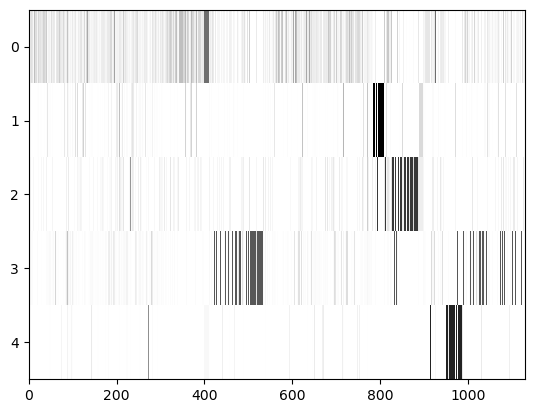

Topic 1     Topic 2       Topic 3  Topic 4     Topic 5   
-------     -------       -------  -------     -------   
jmm2020     fundamental   graham   user172     pcmi      
disruptjmm  question      erica    disruptjmm  deadline  
user36      asking        anti     starts      heels     
hope        things        di       land        programs  
consider    two           user197  user308     extended  
honor       mathematical  dr       people      several   
challenge   user78        racism   thanks      user112   

For LaTeX table...
------------------
jmm2020 & fundamental & graham & user172 \\
disruptjmm & question & erica & disruptjmm \\
user36 & asking & anti & starts \\
hope & things & di & land \\
consider & two & user197 & user308 \\
honor & mathematical & dr & people \\
challenge & user78 & racism & thanks \\
pcmi \\
deadline \\
heels \\
programs \\
extended \\
several \\
user112 \\


In [59]:
top_to_show = 7

plt.imshow(W,aspect='auto',cmap='binary',interpolation='none')
plt.show()

keywords = np.empty((top_to_show+2,groupNum), dtype=object)

for i in range(keywords.shape[1]):
    keywords[0,i] = "Topic " + str(i+1)
    keywords[1,i] = "-------"

for i in range(H.shape[1]):
    col = H[:,i]
    top = col.argsort()
    top = top[-1*top_to_show:][::-1]

    keywords[2:,i] = idx_to_word[top] 


col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for row in keywords:
    print("".join(row[i].ljust(col_widths[i]) for i in range(len(row))))
    
print("")
print("For LaTeX table...")  
print("------------------")
col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(0,4)]) + " \\\\")
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(4,min(8,groupNum))]) + " \\\\")

Create Seed topics (Y matrix)

In [60]:
seed1 = {"trans": 1}
seed2 = {"question": 1}

gt_topic_words= [seed1, seed2]
gt_topic_vectors= [d_to_v(x) for x in gt_topic_words]

Y = np.stack(gt_topic_vectors).T


In [61]:
np.random.seed(1)

model_2 = SSNMF(X_avg.T,groupNum,Y=Y.T,lam=0.5)
N=200
model_2.mult(numiters = N)

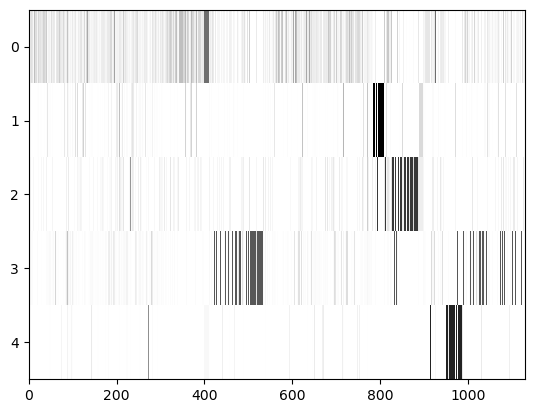

Topic 1     Topic 2       Topic 3  Topic 4     Topic 5   
-------     -------       -------  -------     -------   
jmm2020     fundamental   graham   user172     pcmi      
disruptjmm  question      erica    disruptjmm  deadline  
user36      asking        anti     starts      heels     
hope        things        di       land        programs  
consider    two           user197  user308     extended  
honor       mathematical  dr       people      several   
challenge   user78        racism   thanks      user112   

For LaTeX table...
------------------
jmm2020 & fundamental & graham & user172 \\
disruptjmm & question & erica & disruptjmm \\
user36 & asking & anti & starts \\
hope & things & di & land \\
consider & two & user197 & user308 \\
honor & mathematical & dr & people \\
challenge & user78 & racism & thanks \\
pcmi \\
deadline \\
heels \\
programs \\
extended \\
several \\
user112 \\


In [62]:
S = model_2.A.T
A = model_2.S.T

plt.imshow(S,aspect='auto',cmap='binary',interpolation='none')
plt.show()

keywords = np.empty((top_to_show+2,groupNum), dtype=object)

for i in range(keywords.shape[1]):
    keywords[0,i] = "Topic " + str(i+1)
    keywords[1,i] = "-------"

for i in range(A.shape[1]):
    col = A[:,i]
    top = col.argsort()
    top = top[-1*top_to_show:][::-1]

    keywords[2:,i] = idx_to_word[top] 

col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for row in keywords:
    print("".join(row[i].ljust(col_widths[i]) for i in range(len(row))))
    
print("")
print("For LaTeX table...")  
print("------------------")
col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(0,4)]) + " \\\\")
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(4,min(8,groupNum))]) + " \\\\")

# Changing the seed to test things out

pwr2dppl	user36
sbagley	user75
VictorPiercey1	user76
RG1gal	user112
LoboWithACause	user102
mathprofcarrie	user266
JointMath	user10
WanderingPoint	user172

Seeding connects things to seed1 and Topic 1, which in this first case will be user36. 

In [63]:
seed1 = {"user36": 1}
#seed2 = {"question": 1}

gt_topic_words= [seed1]
gt_topic_vectors= [d_to_v(x) for x in gt_topic_words]

Y = np.stack(gt_topic_vectors).T

In [64]:
np.random.seed(1)

model_2 = SSNMF(X_avg.T,groupNum,Y=Y.T,lam=0.5)
N=200
model_2.mult(numiters = N)

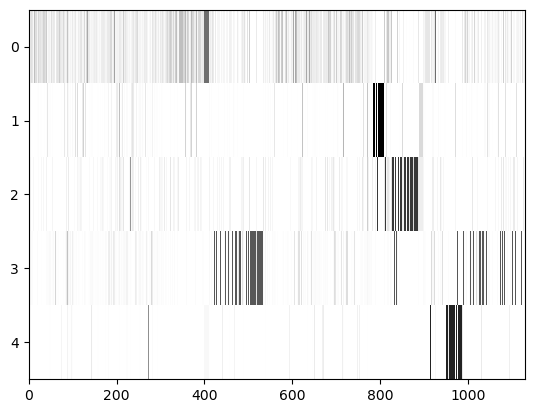

Topic 1     Topic 2       Topic 3  Topic 4     Topic 5   
-------     -------       -------  -------     -------   
jmm2020     fundamental   graham   user172     pcmi      
disruptjmm  question      erica    disruptjmm  deadline  
user36      asking        anti     starts      heels     
hope        things        di       land        programs  
consider    two           user197  user308     extended  
honor       mathematical  dr       people      several   
challenge   user78        racism   thanks      user112   

For LaTeX table...
------------------
jmm2020 & fundamental & graham & user172 \\
disruptjmm & question & erica & disruptjmm \\
user36 & asking & anti & starts \\
hope & things & di & land \\
consider & two & user197 & user308 \\
honor & mathematical & dr & people \\
challenge & user78 & racism & thanks \\
pcmi \\
deadline \\
heels \\
programs \\
extended \\
several \\
user112 \\


In [65]:
S = model_2.A.T
A = model_2.S.T

plt.imshow(S,aspect='auto',cmap='binary',interpolation='none')
plt.show()

keywords = np.empty((top_to_show+2,groupNum), dtype=object)

for i in range(keywords.shape[1]):
    keywords[0,i] = "Topic " + str(i+1)
    keywords[1,i] = "-------"

for i in range(A.shape[1]):
    col = A[:,i]
    top = col.argsort()
    top = top[-1*top_to_show:][::-1]

    keywords[2:,i] = idx_to_word[top] 

col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for row in keywords:
    print("".join(row[i].ljust(col_widths[i]) for i in range(len(row))))
    
print("")
print("For LaTeX table...")  
print("------------------")
col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(0,4)]) + " \\\\")
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(4,min(8,groupNum))]) + " \\\\")

In topic 2, we're hoping to see topics related to user266

In [66]:
seed1 = {"user36": 1}
seed2 = {"user266": 1}
seed3 = {"user75" :1}
seed4 = {"user76" :1}
seed5 = {"user102" :1}

gt_topic_words= [seed1, seed2,seed3,seed4,seed5]
gt_topic_vectors= [d_to_v(x) for x in gt_topic_words]

Y = np.stack(gt_topic_vectors).T

np.random.seed(1)

model_2 = SSNMF(X_avg.T,groupNum,Y=Y.T,lam=0.5)
N=200
model_2.mult(numiters = N)

S = model_2.A.T
A = model_2.S.T

#plt.imshow(S,aspect='auto',cmap='binary',interpolation='none')
#plt.show()

keywords = np.empty((top_to_show+2,groupNum), dtype=object)

for i in range(keywords.shape[1]):
    keywords[0,i] = "Topic " + str(i+1)
    keywords[1,i] = "-------"

for i in range(A.shape[1]):
    col = A[:,i]
    top = col.argsort()
    top = top[-1*top_to_show:][::-1]

    keywords[2:,i] = idx_to_word[top] 

col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for row in keywords:
    print("".join(row[i].ljust(col_widths[i]) for i in range(len(row))))
    
print("")
print("For LaTeX table...")  
print("------------------")
col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(0,4)]) + " \\\\")
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(4,min(8,groupNum))]) + " \\\\")

Topic 1     Topic 2       Topic 3  Topic 4     Topic 5   
-------     -------       -------  -------     -------   
jmm2020     fundamental   graham   user172     pcmi      
disruptjmm  question      erica    disruptjmm  deadline  
user36      asking        anti     starts      heels     
hope        things        di       land        programs  
consider    two           user197  user308     extended  
honor       mathematical  dr       people      several   
challenge   user78        racism   thanks      user112   

For LaTeX table...
------------------
jmm2020 & fundamental & graham & user172 \\
disruptjmm & question & erica & disruptjmm \\
user36 & asking & anti & starts \\
hope & things & di & land \\
consider & two & user197 & user308 \\
honor & mathematical & dr & people \\
challenge & user78 & racism & thanks \\
pcmi \\
deadline \\
heels \\
programs \\
extended \\
several \\
user112 \\


In [40]:
top_to_show=20
seed1 = {"fundamental": 1, "racism": 1}


gt_topic_words= [seed1]
gt_topic_vectors= [d_to_v(x) for x in gt_topic_words]

Y = np.stack(gt_topic_vectors).T

np.random.seed(1)

model_2 = SSNMF(X_avg.T,groupNum,Y=Y.T,lam=0.5)
N=500
model_2.mult(numiters = N)

S2 = model_2.A.T
A2 = model_2.S.T

#plt.imshow(S,aspect='auto',cmap='binary',interpolation='none')
#plt.show()

keywords = np.empty((top_to_show+2,groupNum), dtype=object)

for i in range(keywords.shape[1]):
    keywords[0,i] = "Topic " + str(i+1)
    keywords[1,i] = "-------"

for i in range(A2.shape[1]):
    col = A2[:,i]
    top = col.argsort()
    top = top[-1*top_to_show:][::-1]

    keywords[2:,i] = idx_to_word[top] 

col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for row in keywords:
    print("".join(row[i].ljust(col_widths[i]) for i in range(len(row))))
    
print("")
print("For LaTeX table...")  
print("------------------")
col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(0,4)]) + " \\\\")
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(4,min(8,groupNum))]) + " \\\\")

Topic 1                Topic 2       Topic 3      Topic 4          Topic 5      
-------                -------       -------      -------          -------      
jmm2020                fundamental   graham       user172          deadline     
disruptjmm             question      erica        disruptjmm       extended     
user36                 asking        anti         starts           heels        
hope                   things        di           land             programs     
consider               two           user197      user308          pcmi         
honor                  mathematical  dr           people           several      
challenge              user78        racism       thanks           user112      
diversityandinclusion  disruptjmm    jmm2021      disruptmath      summer       
might                  key           mathematics  user74           interested   
user102                think         user266      talk             know         
math                   talk 

In [37]:
gt_topic_words

[{'fundamental': 1, 'racism': 1}]

# Working on making a function for this

In [70]:
#seed1 = {"user36": 1}
#seed2 = {"user266": 1}
#seed3 = {"user75" :1}
#seed4 = {"user76" :1}
#seed5 = {"user102" :1}

#gt_topic_words= [seed1, seed2,seed3,seed4,seed5]

def make_nmf(gt_topic_words,n,group_Num,top):
    """
    input: seed words, number of iterations, number of topics,
    numper to show in topics
    output: the topics that appeared with the related words.
    """
    groupNum = group_Num
    top_to_show = top
    gt_topic_vectors= [d_to_v(x) for x in gt_topic_words]
    
    Y = np.stack(gt_topic_vectors).T
    
    #np.random.seed(1)
    
    model_2 = SSNMF(X_avg.T,groupNum,Y=Y.T,lam=0.5,random_state=1)
    N=n
    model_2.mult(numiters = N)
    
    S = model_2.A.T
    A = model_2.S.T
    
    #plt.imshow(S,aspect='auto',cmap='binary',interpolation='none')
    #plt.show()
    
    keywords = np.empty((top_to_show+2,groupNum), dtype=object)
    
    for i in range(keywords.shape[1]):
        keywords[0,i] = "Topic " + str(i+1)
        keywords[1,i] = "-------"
    
    for i in range(A.shape[1]):
        col = A[:,i]
        top = col.argsort()
        top = top[-1*top_to_show:][::-1]
    
        keywords[2:,i] = idx_to_word[top] 
    
    col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
    for row in keywords:
        print("".join(row[i].ljust(col_widths[i]) for i in range(len(row))))
        
   # print("")
   # print("For LaTeX table...")  
   # print("------------------")
   # col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
   # for i, row in enumerate(keywords):
   #     if(i >= 2):
   #         print(" & ".join([row[i] for i in range(0,4)]) + " \\\\")
   # for i, row in enumerate(keywords):
    #    if(i >= 2):
     #       print(" & ".join([row[i] for i in range(4,min(8,groupNum))]) + " \\\\")

In [71]:
seed1 = {"asking": 1}
seed2 = {"racism": 1}
seed3 = {"user75" :1}
seed4 = {"land" :1}
seed5 = {"honor" :1}

gt_topic_words= [seed1, seed2,seed3,seed4,seed5]
make_nmf(gt_topic_words,200,5,10)

Topic 1     Topic 2        Topic 3                Topic 4       Topic 5      
-------     -------        -------                -------       -------      
programs    user172        jmm2020                fundamental   erica        
pcmi        disruptjmm     disruptjmm             question      graham       
heels       starts         user36                 asking        anti         
extended    land           hope                   things        di           
deadline    user308        consider               two           user197      
several     people         honor                  mathematical  dr           
user112     thanks         challenge              user78        racism       
summer      user74         diversityandinclusion  disruptjmm    jmm2021      
interested  disruptmath    might                  key           mathematics  
know        participating  user102                think         user266      


In [72]:
seed1 = {"user36": 1}
seed2 = {"user266": 1}
seed3 = {"user75" :1}
seed4 = {"user76" :1}
seed5 = {"user102" :1}

gt_topic_words= [seed1, seed2,seed3,seed4,seed5]
make_nmf(gt_topic_words,200,5,10)

Topic 1       Topic 2     Topic 3      Topic 4      Topic 5                
-------       -------     -------      -------      -------                
fundamental   heels       user172      erica        jmm2020                
question      deadline    disruptjmm   graham       disruptjmm             
asking        programs    starts       anti         user36                 
things        pcmi        land         di           hope                   
two           extended    user308      user197      consider               
mathematical  several     people       dr           honor                  
user78        user112     talk         racism       challenge              
disruptjmm    summer      thanks       jmm2021      diversityandinclusion  
key           interested  disruptmath  mathematics  might                  
think         know        user74       user266      user102                


In [73]:
seed1 = {"user36": 1}
#seed2 = {"user266": 1}
#seed3 = {"user75" :1}
#seed4 = {"user76" :1}
#seed5 = {"user102" :1}

gt_topic_words= [seed1]
make_nmf(gt_topic_words,200,5,10)

Topic 1      Topic 2                Topic 3     Topic 4      Topic 5       
-------      -------                -------     -------      -------       
erica        jmm2020                programs    user172      fundamental   
graham       disruptjmm             heels       disruptjmm   question      
anti         user36                 deadline    starts       asking        
di           hope                   extended    land         things        
user197      consider               pcmi        user308      two           
dr           honor                  several     people       mathematical  
racism       challenge              user112     thanks       user78        
jmm2021      diversityandinclusion  summer      disruptmath  disruptjmm    
mathematics  might                  interested  talk         key           
user266      user102                know        user74       think         


In [74]:
seed1 = {"user36": 1}
seed2 = {"user266": 1}
#seed3 = {"user75" :1}
#seed4 = {"user76" :1}
#seed5 = {"user102" :1}

gt_topic_words= [seed1, seed2]
make_nmf(gt_topic_words,200,5,10)

Topic 1                Topic 2      Topic 3       Topic 4      Topic 5     
-------                -------      -------       -------      -------     
jmm2020                graham       fundamental   user172      programs    
disruptjmm             erica        question      disruptjmm   extended    
user36                 anti         asking        starts       deadline    
hope                   di           things        land         pcmi        
consider               user197      two           user308      heels       
honor                  dr           mathematical  people       several     
challenge              racism       user78        thanks       user112     
diversityandinclusion  jmm2021      disruptjmm    disruptmath  summer      
might                  mathematics  key           talk         interested  
user102                user266      think         user74       know        


In [75]:
seed1 = {"user36": 1}
seed2 = {"user266": 1}
seed3 = {"user75" :1}
#seed4 = {"user76" :1}
#seed5 = {"user102" :1}

gt_topic_words= [seed1, seed2,seed3]
make_nmf(gt_topic_words,200,5,10)

Topic 1                Topic 2       Topic 3      Topic 4      Topic 5     
-------                -------       -------      -------      -------     
jmm2020                fundamental   graham       user172      programs    
disruptjmm             question      erica        disruptjmm   deadline    
user36                 asking        anti         starts       pcmi        
hope                   things        di           land         heels       
consider               two           user197      user308      extended    
honor                  mathematical  dr           people       several     
challenge              user78        racism       thanks       user112     
diversityandinclusion  disruptjmm    jmm2021      disruptmath  summer      
might                  key           mathematics  user74       interested  
user102                think         user266      talk         know        


In [76]:
seed1 = {"user36": 1}
seed2 = {"user266": 1}
seed3 = {"user75" :1}
seed4 = {"user76" :1}
#seed5 = {"user102" :1}

gt_topic_words= [seed1, seed2,seed3,seed4]
make_nmf(gt_topic_words,200,5,10)

Topic 1      Topic 2       Topic 3      Topic 4                Topic 5     
-------      -------       -------      -------                -------     
user172      fundamental   graham       jmm2020                heels       
disruptjmm   question      erica        disruptjmm             deadline    
starts       asking        anti         user36                 extended    
land         things        di           hope                   programs    
user308      two           user197      consider               pcmi        
people       mathematical  dr           honor                  several     
thanks       user78        racism       challenge              user112     
disruptmath  disruptjmm    jmm2021      diversityandinclusion  summer      
talk         key           mathematics  might                  interested  
user74       think         user266      user102                know        
